In [1]:
import random, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch, transformers, ultralytics

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU found")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| ultralytics", ultralytics.__version__)

device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU
torch 2.15.0+cu132 | transformers 5.22.2 | ultralytics 8.4.204


In [2]:
ROOT = Path.cwd()
RESULTS = ROOT / "results"      # every metric and table we produce gets saved here
DATASETS = ROOT / "datasets"    # raw downloads go here
for p in (RESULTS, DATASETS):
    p.mkdir(exist_ok=True)
print(ROOT)

/run/media/chandran/Personal/Academics/Academics sem5/HS202_SIH2026/HS202_SIH2026


In [3]:
from transformers import MobileNetV2ImageProcessor, MobileNetV2ForImageClassification

DISEASE_MODEL = "linkanjarad/mobilenet_v2_1.0_224-plant-disease-identification"
processor = MobileNetV2ImageProcessor.from_pretrained(DISEASE_MODEL)
model = MobileNetV2ForImageClassification.from_pretrained(DISEASE_MODEL).to(device).eval()

id2label = model.config.id2label
print("number of classes:", len(id2label))
print(processor)

preprocessor_config.json:   0%|          | 0.00/408 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 9.34MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

number of classes: 38
MobileNetV2ImageProcessor {
  "crop_size": {
    "height": 224,
    "width": 224
  },
  "do_center_crop": true,
  "do_normalize": true,
  "do_reduce_labels": false,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "MobileNetV2ImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 256
  }
}



In [4]:
labels_df = (pd.DataFrame({"idx": list(id2label.keys()), "raw_label": list(id2label.values())})
               .sort_values("idx").reset_index(drop=True))
low = labels_df.raw_label.str.lower()
labels_df["has_triple_underscore"] = labels_df.raw_label.str.contains("___")
labels_df["has_with"] = low.str.contains(" with ")
labels_df["mentions_healthy"] = low.str.contains("healthy")

pd.set_option("display.max_rows", None, "display.width", 200)
labels_df

,idx,raw_label,has_triple_underscore,has_with,mentions_healthy
0,0,Apple Scab,False,False,False
1,1,Apple with Black Rot,False,True,False
2,2,Cedar Apple Rust,False,False,False
3,3,Healthy Apple,False,False,True
4,4,Healthy Blueberry Plant,False,False,True
5,5,Cherry with Powdery Mildew,False,True,False
6,6,Healthy Cherry Plant,False,False,True
7,7,Corn (Maize) with Cercospora and Gray Leaf Spot,False,True,False
8,8,Corn (Maize) with Common Rust,False,True,False
9,9,Corn (Maize) with Northern Leaf Blight,False,True,False


In [5]:
def parse_label_current(raw_label: str):
    raw_label = raw_label.strip()
    if "___" in raw_label:
        plant_part, disease_part = raw_label.split("___", 1)
        plant = plant_part.replace("_", " ").replace("(", "").replace(")", "").strip()
        disease_raw = disease_part.replace("_", " ").strip()
    elif " with " in raw_label.lower():
        idx = raw_label.lower().index(" with ")
        plant = raw_label[:idx].strip()
        disease_raw = raw_label[idx + len(" with "):].strip()
    else:
        plant = "Unknown Plant"
        disease_raw = raw_label
    disease = "Healthy" if disease_raw.lower() == "healthy" else disease_raw.title()
    return plant, disease

parsed = labels_df.raw_label.apply(parse_label_current)
labels_df["plant_parsed"] = [p for p, _ in parsed]
labels_df["disease_parsed"] = [d for _, d in parsed]
labels_df["healthy_detected"] = labels_df.disease_parsed.str.lower().eq("healthy")
labels_df["parse_failed"] = labels_df.plant_parsed.eq("Unknown Plant")

print("parse failures:", labels_df.parse_failed.sum(), "of", len(labels_df))
print("labels that mention 'healthy' but aren't detected as healthy:",
      (labels_df.mentions_healthy & ~labels_df.healthy_detected).sum())
labels_df[["raw_label", "plant_parsed", "disease_parsed", "healthy_detected", "parse_failed"]]

parse failures: 16 of 38
labels that mention 'healthy' but aren't detected as healthy: 12


,raw_label,plant_parsed,disease_parsed,healthy_detected,parse_failed
0,Apple Scab,Unknown Plant,Apple Scab,False,True
1,Apple with Black Rot,Apple,Black Rot,False,False
2,Cedar Apple Rust,Unknown Plant,Cedar Apple Rust,False,True
3,Healthy Apple,Unknown Plant,Healthy Apple,False,True
4,Healthy Blueberry Plant,Unknown Plant,Healthy Blueberry Plant,False,True
5,Cherry with Powdery Mildew,Cherry,Powdery Mildew,False,False
6,Healthy Cherry Plant,Unknown Plant,Healthy Cherry Plant,False,True
7,Corn (Maize) with Cercospora and Gray Leaf Spot,Corn (Maize),Cercospora And Gray Leaf Spot,False,False
8,Corn (Maize) with Common Rust,Corn (Maize),Common Rust,False,False
9,Corn (Maize) with Northern Leaf Blight,Corn (Maize),Northern Leaf Blight,False,False


In [6]:
import treatments

def kb_has(row):
    return treatments.get_treatment(row.plant_parsed, row.disease_parsed) is not None

labels_df["kb_match"] = labels_df.apply(kb_has, axis=1)
labels_df["will_escalate_even_if_confident"] = (~labels_df.healthy_detected) & (~labels_df.kb_match)

print("labels with a KB answer:", labels_df.kb_match.sum())
print("labels that always escalate:", labels_df.will_escalate_even_if_confident.sum())
labels_df[labels_df.will_escalate_even_if_confident][["raw_label", "plant_parsed", "disease_parsed"]]

labels with a KB answer: 15
labels that always escalate: 23


,raw_label,plant_parsed,disease_parsed
0,Apple Scab,Unknown Plant,Apple Scab
2,Cedar Apple Rust,Unknown Plant,Cedar Apple Rust
3,Healthy Apple,Unknown Plant,Healthy Apple
4,Healthy Blueberry Plant,Unknown Plant,Healthy Blueberry Plant
6,Healthy Cherry Plant,Unknown Plant,Healthy Cherry Plant
7,Corn (Maize) with Cercospora and Gray Leaf Spot,Corn (Maize),Cercospora And Gray Leaf Spot
8,Corn (Maize) with Common Rust,Corn (Maize),Common Rust
9,Corn (Maize) with Northern Leaf Blight,Corn (Maize),Northern Leaf Blight
10,Healthy Corn (Maize) Plant,Unknown Plant,Healthy Corn (Maize) Plant
13,Grape with Isariopsis Leaf Spot,Grape,Isariopsis Leaf Spot


In [7]:
labels_df.to_csv(RESULTS / "stage1_labels.csv", index=False)

In [8]:
CANONICAL = {
    0: ("Apple", "Apple Scab"),              1: ("Apple", "Black Rot"),
    2: ("Apple", "Cedar Apple Rust"),        3: ("Apple", "Healthy"),
    4: ("Blueberry", "Healthy"),             5: ("Cherry", "Powdery Mildew"),
    6: ("Cherry", "Healthy"),
    7: ("Corn", "Cercospora Leaf Spot (Gray Leaf Spot)"),
    8: ("Corn", "Common Rust"),              9: ("Corn", "Northern Leaf Blight"),
    10: ("Corn", "Healthy"),                 11: ("Grape", "Black Rot"),
    12: ("Grape", "Esca (Black Measles)"),
    13: ("Grape", "Leaf Blight (Isariopsis Leaf Spot)"),
    14: ("Grape", "Healthy"),
    15: ("Orange", "Haunglongbing (Citrus Greening)"),
    16: ("Peach", "Bacterial Spot"),         17: ("Peach", "Healthy"),
    18: ("Pepper", "Bacterial Spot"),        19: ("Pepper", "Healthy"),
    20: ("Potato", "Early Blight"),          21: ("Potato", "Late Blight"),
    22: ("Potato", "Healthy"),               23: ("Raspberry", "Healthy"),
    24: ("Soybean", "Healthy"),              25: ("Squash", "Powdery Mildew"),
    26: ("Strawberry", "Leaf Scorch"),       27: ("Strawberry", "Healthy"),
    28: ("Tomato", "Bacterial Spot"),        29: ("Tomato", "Early Blight"),
    30: ("Tomato", "Late Blight"),           31: ("Tomato", "Leaf Mold"),
    32: ("Tomato", "Septoria Leaf Spot"),
    33: ("Tomato", "Spider Mites (Two-Spotted Spider Mite)"),
    34: ("Tomato", "Target Spot"),
    35: ("Tomato", "Tomato Yellow Leaf Curl Virus"),
    36: ("Tomato", "Tomato Mosaic Virus"),   37: ("Tomato", "Healthy"),
}

labels_df["crop"] = labels_df.idx.map(lambda i: CANONICAL[i][0])
labels_df["disease"] = labels_df.idx.map(lambda i: CANONICAL[i][1])
labels_df["is_healthy"] = labels_df.disease.eq("Healthy")
labels_df["kb_match"] = labels_df.apply(
    lambda r: r.is_healthy or treatments.get_treatment(r.crop, r.disease) is not None, axis=1)

# Validation: each assert catches a different kind of typo
assert set(CANONICAL) == set(labels_df.idx) and len(CANONICAL) == 38
assert all(c.lower() in r.lower() for c, r in zip(labels_df.crop, labels_df.raw_label)), "crop not in raw label"
assert labels_df.is_healthy.eq(labels_df.mentions_healthy).all(), "healthy flag disagrees with raw label"
assert not labels_df.duplicated(["crop", "disease"]).any(), "duplicate (crop, disease)"

print("crops:", labels_df.crop.nunique(), "| healthy classes:", labels_df.is_healthy.sum())
print("labels with no answer path:", (~labels_df.kb_match).sum(), "(expect 0)")
labels_df[["idx", "raw_label", "crop", "disease", "is_healthy", "kb_match"]].to_csv(
    RESULTS / "stage1_canonical_labels.csv", index=False)
labels_df[["raw_label", "crop", "disease", "is_healthy", "kb_match"]]

crops: 14 | healthy classes: 12
labels with no answer path: 0 (expect 0)


,raw_label,crop,disease,is_healthy,kb_match
0,Apple Scab,Apple,Apple Scab,False,True
1,Apple with Black Rot,Apple,Black Rot,False,True
2,Cedar Apple Rust,Apple,Cedar Apple Rust,False,True
3,Healthy Apple,Apple,Healthy,True,True
4,Healthy Blueberry Plant,Blueberry,Healthy,True,True
5,Cherry with Powdery Mildew,Cherry,Powdery Mildew,False,True
6,Healthy Cherry Plant,Cherry,Healthy,True,True
7,Corn (Maize) with Cercospora and Gray Leaf Spot,Corn,Cercospora Leaf Spot (Gray Leaf Spot),False,True
8,Corn (Maize) with Common Rust,Corn,Common Rust,False,True
9,Corn (Maize) with Northern Leaf Blight,Corn,Northern Leaf Blight,False,True


In [9]:
from ultralytics import YOLO
from huggingface_hub import hf_hub_download

PEST_REPO, PEST_FILE = "Yudsky/pest-detection-yolo11", "best.pt"
pest_path = hf_hub_download(repo_id=PEST_REPO, filename=PEST_FILE)
pest_model = YOLO(pest_path)

print("task:", pest_model.task)
print("num classes:", len(pest_model.names))

# Training metadata saved inside the checkpoint (may be missing)
try:
    ta = pest_model.ckpt.get("train_args", {})
    print({k: ta.get(k) for k in ["data", "imgsz", "epochs", "batch", "model"]})
except Exception as e:
    print("no train_args:", e)

best.pt: reconstructing file:   0%|          |  0.00B / 51.3MB            

best.pt: downloading bytes:           |  0.00B            

task: detect
num classes: 102
{'data': '/kaggle/input/yolo-train/ip102.yaml', 'imgsz': 512, 'epochs': 30, 'batch': 64, 'model': 'yolo11l.pt'}


In [10]:
pest_df = pd.DataFrame({"class_id": list(pest_model.names.keys()),
                        "pest": list(pest_model.names.values())})
pest_df.to_csv(RESULTS / "stage2_pest_classes.csv", index=False)
print(len(pest_df), "classes")
pest_df

102 classes


,class_id,pest
0,0,rice leaf roller
1,1,rice leaf caterpillar
2,2,paddy stem maggot
3,3,asiatic rice borer
4,4,yellow rice borer
5,5,rice gall midge
6,6,Rice Stemfly
7,7,brown plant hopper
8,8,white backed plant hopper
9,9,small brown plant hopper


3 images

=== conf threshold 0.25 ===
images.jpeg -> [('flax budworm', 35.9)]
leaf.jpeg -> nothing
leaf1.jpg -> [('Aleurocanthus spiniferus', 96.2)]

=== conf threshold 0.05 ===
images.jpeg -> [('flax budworm', 35.9)]
leaf.jpeg -> [('beet army worm', 24.4), ('flax budworm', 15.7), ('Adristyrannus', 12.6)]
leaf1.jpg -> [('Aleurocanthus spiniferus', 96.2), ('Chrysomphalus aonidum', 13.5)]


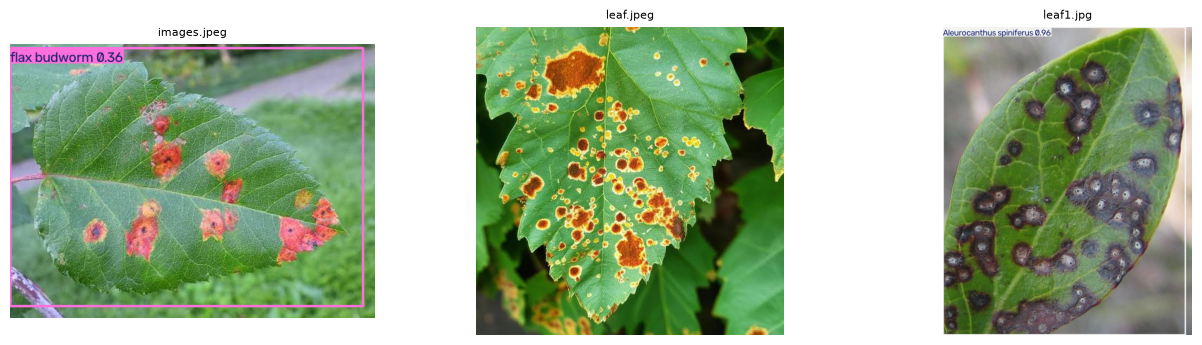

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

SAMPLES = DATASETS / "samples"
imgs = sorted(p for p in SAMPLES.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
print(len(imgs), "images")

for conf in (0.25, 0.05):
    print(f"\n=== conf threshold {conf} ===")
    for p in imgs:
        r = pest_model.predict(source=str(p), conf=conf, device=0 if device == "cuda" else "cpu", verbose=False)[0]
        found = [(r.names[int(b.cls[0])], round(float(b.conf[0]) * 100, 1)) for b in r.boxes]
        print(p.name, "->", found if found else "nothing")

# Draw the 0.25 result for the first few images
fig, axes = plt.subplots(1, min(len(imgs), 4), figsize=(16, 4), squeeze=False)
for ax, p in zip(axes[0], imgs[:4]):
    r = pest_model.predict(source=str(p), conf=0.25, device=0 if device == "cuda" else "cpu", verbose=False)[0]
    ax.imshow(r.plot()[..., ::-1]); ax.set_title(p.name, fontsize=8); ax.axis("off")
plt.show()

In [12]:
def predict_disease(img, top_k=3):
    inputs = processor(images=img, return_tensors="pt").to(device)
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits, dim=-1)[0]
    top = torch.topk(probs, top_k)
    return [(CANONICAL[i][0], CANONICAL[i][1], round(p * 100, 1))
            for p, i in zip(top.values.tolist(), top.indices.tolist())]

for p in imgs:
    print(p.name, "->", predict_disease(Image.open(p).convert("RGB")))

images.jpeg -> [('Apple', 'Cedar Apple Rust', 59.9), ('Grape', 'Esca (Black Measles)', 12.0), ('Pepper', 'Bacterial Spot', 4.1)]
leaf.jpeg -> [('Apple', 'Cedar Apple Rust', 40.1), ('Corn', 'Common Rust', 26.8), ('Pepper', 'Bacterial Spot', 22.5)]
leaf1.jpg -> [('Grape', 'Black Rot', 81.0), ('Potato', 'Early Blight', 4.8), ('Strawberry', 'Leaf Scorch', 4.1)]


In [13]:
def run_pest(p, conf=0.05, imgsz=512):
    r = pest_model.predict(str(p), conf=conf, imgsz=imgsz,
                           device=0 if device == "cuda" else "cpu", verbose=False)[0]
    H, W = r.orig_shape
    out = []
    for b in r.boxes:
        x1, y1, x2, y2 = b.xyxy[0].tolist()
        out.append((r.names[int(b.cls[0])], round(float(b.conf[0]) * 100, 1),
                    round((x2 - x1) * (y2 - y1) / (W * H), 2)))   # box area / image area
    return out

for p in imgs:
    for sz in (512, 640):
        print(p.name, f"imgsz={sz}", "->", run_pest(p, imgsz=sz))

images.jpeg imgsz=512 -> [('flax budworm', 35.9, 0.91)]
images.jpeg imgsz=640 -> [('Adristyrannus', 10.7, 0.83), ('flax budworm', 10.0, 0.75)]
leaf.jpeg imgsz=512 -> [('beet army worm', 24.4, 0.89), ('flax budworm', 15.7, 0.89), ('Adristyrannus', 12.6, 0.88)]
leaf.jpeg imgsz=640 -> [('flax budworm', 5.1, 0.61)]
leaf1.jpg imgsz=512 -> [('Aleurocanthus spiniferus', 96.2, 0.97), ('Chrysomphalus aonidum', 13.5, 0.02)]
leaf1.jpg imgsz=640 -> [('Aleurocanthus spiniferus', 22.6, 0.77), ('Ceroplastes rubens', 13.2, 0.03), ('Ceroplastes rubens', 10.6, 0.05), ('Ceroplastes rubens', 6.4, 0.01), ('Chrysomphalus aonidum', 5.0, 0.02)]


In [14]:
import requests, zipfile, time
from pathlib import Path

ZIP_DIR  =DATASETS                 # short path on purpose; change the drive if you like
ZIP_DIR.mkdir(parents=True, exist_ok=True)
ZIP_FILE = ZIP_DIR / "plantdoc.zip"
PD_ROOT  = ZIP_DIR / "plantdoc"

def download(url, dest):
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("Content-Length", 0))
        done, t0 = 0, time.time()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(1 << 20):          # 1 MB at a time
                f.write(chunk); done += len(chunk)
                mb, speed = done / 1e6, done / 1e6 / max(time.time() - t0, 1e-6)
                if total:
                    print(f"\r{mb:7.1f} / {total/1e6:.1f} MB  ({done/total:5.1%})  left: {(total-done)/1e6:7.1f} MB  {speed:.1f} MB/s", end="", flush=True)
                else:
                    print(f"\r{mb:7.1f} MB downloaded (total size not reported)  {speed:.1f} MB/s", end="", flush=True)
    print()

if not ZIP_FILE.exists():
    for branch in ("master", "main"):
        try:
            download(f"https://github.com/pratikkayal/PlantDoc-Dataset/archive/refs/heads/{branch}.zip", ZIP_FILE)
            print("branch:", branch); break
        except requests.HTTPError as e:
            print(branch, "->", e)
            ZIP_FILE.unlink(missing_ok=True)

assert ZIP_FILE.exists(), "download failed on both branches"

# Extract with a count of files done / left
with zipfile.ZipFile(ZIP_FILE) as z:
    members = z.infolist()
    for i, m in enumerate(members, 1):
        z.extract(m, PD_ROOT)
        if i % 100 == 0 or i == len(members):
            print(f"\rextracted {i}/{len(members)}  left: {len(members)-i}", end="", flush=True)
print()

IMG_EXT = {".jpg", ".jpeg", ".png"}
n_files = sum(1 for f in PD_ROOT.rglob("*") if f.suffix.lower() in IMG_EXT)
print(f"done: {n_files} images, {ZIP_FILE.stat().st_size/1e6:.0f} MB zip")
print([p.name for p in sorted(PD_ROOT.iterdir())])

extracted 2639/2639  left: 0999
done: 2579 images, 984 MB zip
['PlantDoc-Dataset-master']


In [15]:
import zipfile
from pathlib import Path

candidates = []
for base in (DATASETS, ROOT):
    candidates += list(base.glob("plantdoc*.zip"))
print("found:", [str(c) for c in candidates])

ZIP_FILE = None
for c in candidates:
    if zipfile.is_zipfile(c):
        with zipfile.ZipFile(c) as z:
            n = len(z.infolist())
        print(f"{c}: valid zip, {n} entries, {c.stat().st_size/1e6:.0f} MB")
        ZIP_FILE = c
        break
assert ZIP_FILE, "No valid ZIP found. Run the ZIP download cell once more, then redo this step."

found: ['/run/media/chandran/Personal/Academics/Academics sem5/HS202_SIH2026/HS202_SIH2026/datasets/plantdoc.zip']
/run/media/chandran/Personal/Academics/Academics sem5/HS202_SIH2026/HS202_SIH2026/datasets/plantdoc.zip: valid zip, 2639 entries, 984 MB


In [16]:
import shutil, csv
OUT = DATASETS / "plantdoc_flat"
if OUT.exists():
    shutil.rmtree(OUT, ignore_errors=True)
OUT.mkdir(parents=True)

manifest = []
with zipfile.ZipFile(ZIP_FILE) as z:
    members = [m for m in z.infolist() if not m.is_dir()]
    for i, m in enumerate(members, 1):
        parts = Path(m.filename).parts
        if len(parts) >= 4 and parts[1] in ("train", "test"):
            split, cls = parts[1], parts[2]
            dest = OUT / split / cls / f"{i:05d}{Path(m.filename).suffix.lower()}"
        else:
            dest = OUT / "_other" / f"{i:05d}_{Path(m.filename).name[:40]}"
        dest.parent.mkdir(parents=True, exist_ok=True)
        with z.open(m) as src, open(dest, "wb") as dst:
            shutil.copyfileobj(src, dst)
        manifest.append((str(dest.relative_to(OUT)), m.filename))
        if i % 100 == 0 or i == len(members):
            print(f"\rextracted {i}/{len(members)}  left: {len(members)-i}", end="", flush=True)
print()

with open(RESULTS / "stage3_plantdoc_manifest.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["new_path", "original_zip_path"]); w.writerows(manifest)
print("extraction finished")

extracted 2581/2581  left: 0111
extraction finished


In [17]:
PD_ROOT = OUT
IMG_EXT = {".jpg", ".jpeg", ".png"}

imgs_all = [f for f in PD_ROOT.rglob("*") if f.suffix.lower() in IMG_EXT]
by_split = {s: sum(1 for f in imgs_all if f.relative_to(PD_ROOT).parts[0] == s) for s in ("train", "test", "_other")}
classes = sorted({f.parent.name for f in imgs_all if f.relative_to(PD_ROOT).parts[0] in ("train", "test")})

print("images total:", len(imgs_all), "| by split:", by_split, "| published total: 2,598")
print("classes:", len(classes))
print(classes)
print("longest path:", max(len(str(f)) for f in imgs_all), "chars (must be < 260)")
assert by_split["train"] > 0 and by_split["test"] > 0, "train/test split missing"

images total: 2579 | by split: {'train': 2342, 'test': 236, '_other': 1} | published total: 2,598
classes: 28
['Apple Scab Leaf', 'Apple leaf', 'Apple rust leaf', 'Bell_pepper leaf', 'Bell_pepper leaf spot', 'Blueberry leaf', 'Cherry leaf', 'Corn Gray leaf spot', 'Corn leaf blight', 'Corn rust leaf', 'Peach leaf', 'Potato leaf early blight', 'Potato leaf late blight', 'Raspberry leaf', 'Soyabean leaf', 'Squash Powdery mildew leaf', 'Strawberry leaf', 'Tomato Early blight leaf', 'Tomato Septoria leaf spot', 'Tomato leaf', 'Tomato leaf bacterial spot', 'Tomato leaf late blight', 'Tomato leaf mosaic virus', 'Tomato leaf yellow virus', 'Tomato mold leaf', 'Tomato two spotted spider mites leaf', 'grape leaf', 'grape leaf black rot']
longest path: 157 chars (must be < 260)


In [18]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
rows = []
for split in ("train", "test"):
    for cls_dir in sorted((PD_ROOT / split).iterdir()):
        if cls_dir.is_dir():
            n = sum(1 for f in cls_dir.rglob("*") if f.suffix.lower() in IMG_EXT)
            rows.append((split, cls_dir.name, n))

counts = pd.DataFrame(rows, columns=["split", "class", "n"])
table = counts.pivot_table(index="class", columns="split", values="n", fill_value=0).astype(int)
table["total"] = table.sum(axis=1)
print("classes:", len(table), "| train:", table["train"].sum(), "| test:", table["test"].sum(),
      "| total:", table["total"].sum(), "(published: 2,598)")
print("imbalance (max/min class):", round(table.total.max() / max(table.total.min(), 1), 1))
table.sort_values("total", ascending=False).to_csv(RESULTS / "stage3_plantdoc_counts.csv")
table.sort_values("total", ascending=False)

classes: 28 | train: 2342 | test: 236 | total: 2578 (published: 2,598)
imbalance (max/min class): 96.0


split,test,train,total
class,,,
Corn leaf blight,12,180,192
Tomato Septoria leaf spot,11,140,151
Squash Powdery mildew leaf,6,124,130
Raspberry leaf,7,112,119
Potato leaf early blight,8,109,117
Blueberry leaf,11,106,117
Corn rust leaf,10,106,116
Peach leaf,9,103,112
Tomato leaf late blight,10,101,111


In [19]:
recs = []
for f in PD_ROOT.rglob("*"):
    if f.suffix.lower() in IMG_EXT and f.parent.parent.name in ("train", "test"):
        try:
            with Image.open(f) as im:
                im.verify()
            with Image.open(f) as im:
                w, h = im.size
            recs.append((f, f.parent.parent.name, f.parent.name, w, h))
        except Exception as e:
            print("BAD:", f, e)

img_df = pd.DataFrame(recs, columns=["path", "split", "cls", "w", "h"])
print(len(img_df), "readable images")
print(img_df[["w", "h"]].describe().round(0))
print("smaller than 224px on the short side:", (img_df[["w", "h"]].min(axis=1) < 224).sum())

2578 readable images
            w       h
count  2578.0  2578.0
mean   1068.0   911.0
std     869.0   754.0
min     115.0    69.0
25%     500.0   403.0
50%     800.0   667.0
75%    1300.0  1181.0
max    6000.0  6000.0
smaller than 224px on the short side: 111


In [20]:
import hashlib
img_df["md5"] = img_df.path.map(lambda p: hashlib.md5(p.read_bytes()).hexdigest())
dups = img_df[img_df.duplicated("md5", keep=False)]
leak = dups.groupby("md5").split.nunique().gt(1).sum()
print("images involved in exact duplication:", len(dups))
print("duplicate groups spanning both train and test (leakage):", leak)

images involved in exact duplication: 24
duplicate groups spanning both train and test (leakage): 11


In [21]:
PD2IDX = {
 'Apple Scab Leaf': 0,  'Apple rust leaf': 2,  'Apple leaf': 3,
 'Blueberry leaf': 4,   'Cherry leaf': 6,
 'Corn Gray leaf spot': 7, 'Corn rust leaf': 8, 'Corn leaf blight': 9,
 'grape leaf black rot': 11, 'grape leaf': 14,
 'Peach leaf': 17,
 'Bell_pepper leaf spot': 18, 'Bell_pepper leaf': 19,
 'Potato leaf early blight': 20, 'Potato leaf late blight': 21,
 'Raspberry leaf': 23, 'Soyabean leaf': 24, 'Squash Powdery mildew leaf': 25,
 'Strawberry leaf': 27,
 'Tomato leaf bacterial spot': 28, 'Tomato Early blight leaf': 29,
 'Tomato leaf late blight': 30, 'Tomato mold leaf': 31,
 'Tomato Septoria leaf spot': 32, 'Tomato two spotted spider mites leaf': 33,
 'Tomato leaf yellow virus': 35, 'Tomato leaf mosaic virus': 36, 'Tomato leaf': 37,
}
assert set(PD2IDX) == set(classes), set(classes) ^ set(PD2IDX)

eval_df = img_df.copy()
conflicts = eval_df.groupby("md5").cls.nunique().gt(1)
print("duplicate files with CONFLICTING labels:", conflicts.sum())
eval_df = eval_df[~eval_df.md5.isin(conflicts[conflicts].index)]
eval_df = eval_df.drop_duplicates("md5")
eval_df = eval_df[eval_df.cls != "Tomato two spotted spider mites leaf"]
eval_df["true_idx"] = eval_df.cls.map(PD2IDX)
eval_df["true_crop"] = eval_df.true_idx.map(lambda i: CANONICAL[i][0])
eval_df["true_healthy"] = eval_df.true_idx.map(lambda i: CANONICAL[i][1] == "Healthy")
eval_df = eval_df.reset_index(drop=True)

print("eval images:", len(eval_df), "| classes:", eval_df.true_idx.nunique())
print("never covered by PlantDoc:", sorted(set(range(38)) - set(PD2IDX.values())))

duplicate files with CONFLICTING labels: 9
eval images: 2555 | classes: 27
never covered by PlantDoc: [1, 5, 10, 12, 13, 15, 16, 22, 26, 34]


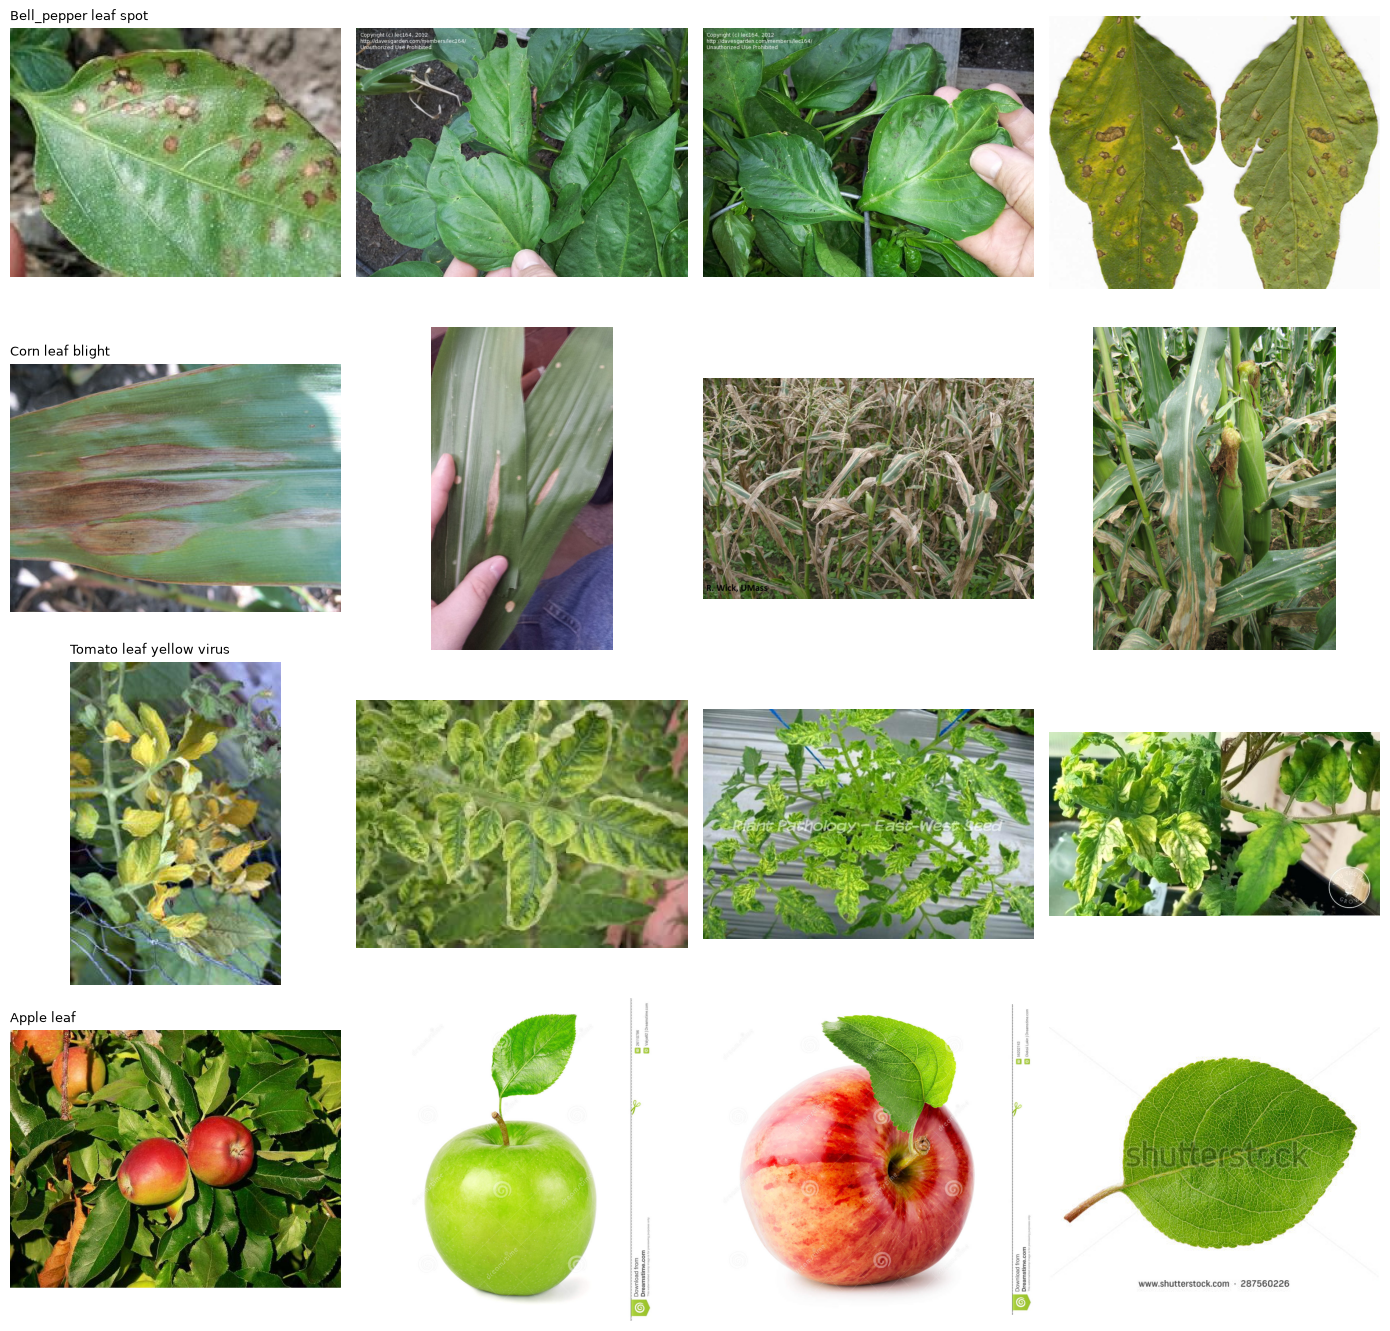

In [22]:
check = ["Bell_pepper leaf spot", "Corn leaf blight", "Tomato leaf yellow virus", "Apple leaf"]
fig, axes = plt.subplots(len(check), 4, figsize=(14, 3.4 * len(check)))
for r, c in enumerate(check):
    for k, p in enumerate(eval_df[eval_df.cls == c].path.head(4)):
        axes[r][k].imshow(Image.open(p).convert("RGB")); axes[r][k].axis("off")
        if k == 0: axes[r][k].set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

In [23]:
B = 16
paths = eval_df.path.tolist()
chunks = []
for s in range(0, len(paths), B):
    batch = []
    for p in paths[s:s+B]:
        im = Image.open(p).convert("RGB")
        im.thumbnail((1024, 1024))          # avoids decoding 6000px images into RAM; the processor shrinks to 256 anyway
        batch.append(im)
    inputs = processor(images=batch, return_tensors="pt").to(device)
    with torch.no_grad():
        chunks.append(torch.softmax(model(**inputs).logits, dim=-1).cpu())
    done = min(s + B, len(paths))
    print(f"\r{done}/{len(paths)} done, {len(paths)-done} left", end="", flush=True)
print()
probs = torch.cat(chunks).numpy()
assert probs.shape == (len(eval_df), 38) and np.allclose(probs.sum(1), 1, atol=1e-3)
np.save(RESULTS / "stage4_probs.npy", probs)

2555/2555 done, 0 leftttt


In [24]:
from sklearn.metrics import classification_report

y_true = eval_df.true_idx.values
y_pred = probs.argmax(1)
conf   = probs.max(1) * 100
top3   = (np.argsort(-probs, 1)[:, :3] == y_true[:, None]).any(1)

pred_crop    = np.array([CANONICAL[i][0] for i in y_pred])
pred_healthy = np.array([CANONICAL[i][1] == "Healthy" for i in y_pred])

print(f"top-1 accuracy:        {(y_pred == y_true).mean():.1%}")
print(f"top-3 accuracy:        {top3.mean():.1%}")
print(f"right crop:            {(pred_crop == eval_df.true_crop.values).mean():.1%}")
print(f"healthy-vs-diseased:   {(pred_healthy == eval_df.true_healthy.values).mean():.1%}")
print(f"predicted a class PlantDoc has no data for: {(~np.isin(y_pred, list(PD2IDX.values()))).sum()}")

print("\nConfidence gate (the 70% rule in care_advisor):")
for t in (50, 70, 90):
    m = conf >= t
    print(f"  conf >= {t}: answers {m.mean():.0%} of images, correct {(y_pred[m] == y_true[m]).mean():.1%}")
print("  confident AND wrong (>=70%):", ((conf >= 70) & (y_pred != y_true)).sum())

labels = sorted(set(y_true))
print("\n", classification_report(y_true, y_pred, labels=labels,
      target_names=[labels_df.raw_label[i] for i in labels], zero_division=0, digits=2))

res = eval_df[["path", "cls", "true_idx"]].assign(pred_idx=y_pred, conf=conf.round(1))
res.to_csv(RESULTS / "stage4_predictions.csv", index=False)
wrong = res[res.true_idx != res.pred_idx]
top_conf = (wrong.assign(true=wrong.true_idx.map(lambda i: labels_df.raw_label[i]),
                         pred=wrong.pred_idx.map(lambda i: labels_df.raw_label[i]))
            .groupby(["true", "pred"]).size().sort_values(ascending=False).head(12))
top_conf

top-1 accuracy:        25.1%
top-3 accuracy:        46.2%
right crop:            44.8%
healthy-vs-diseased:   78.2%
predicted a class PlantDoc has no data for: 256

Confidence gate (the 70% rule in care_advisor):
  conf >= 50: answers 57% of images, correct 32.1%
  conf >= 70: answers 36% of images, correct 34.9%
  conf >= 90: answers 15% of images, correct 46.4%
  confident AND wrong (>=70%): 595

                                                  precision    recall  f1-score   support

                                     Apple Scab       0.25      0.29      0.27        93
                               Cedar Apple Rust       0.30      0.30      0.30        89
                                  Healthy Apple       0.54      0.08      0.13        91
                        Healthy Blueberry Plant       0.18      0.16      0.17       116
                           Healthy Cherry Plant       0.08      0.02      0.03        57
Corn (Maize) with Cercospora and Gray Leaf Spot       0.25    

true                                    pred                                           
Corn (Maize) with Northern Leaf Blight  Corn (Maize) with Cercospora and Gray Leaf Spot    91
Healthy Blueberry Plant                 Grape with Black Rot                               44
Corn (Maize) with Common Rust           Corn (Maize) with Cercospora and Gray Leaf Spot    41
Potato with Late Blight                 Tomato with Late Blight                            34
Tomato with Bacterial Spot              Tomato with Septoria Leaf Spot                     31
Tomato Yellow Leaf Curl Virus           Squash with Powdery Mildew                         28
Tomato with Early Blight                Tomato with Septoria Leaf Spot                     24
Corn (Maize) with Northern Leaf Blight  Corn (Maize) with Common Rust                      23
Tomato with Leaf Mold                   Tomato with Late Blight                            22
Healthy Apple                           Healthy Blueberry Plant   

In [25]:
true_h = eval_df.true_healthy.values
print(f"always-say-'diseased' baseline:                {(~true_h).mean():.1%}")
print(f"diseased leaves flagged diseased:              {(~pred_healthy[~true_h]).mean():.1%}")
print(f"diseased leaves called HEALTHY (dangerous):    {pred_healthy[~true_h].mean():.1%}")
print(f"healthy leaves called healthy:                 {pred_healthy[true_h].mean():.1%}")

cal = pd.DataFrame({"conf": conf, "correct": (y_pred == y_true)})
cal["bin"] = pd.cut(cal.conf, [0, 30, 50, 70, 90, 100.01], right=False)
g = cal.groupby("bin", observed=True).agg(n=("correct", "size"),
                                          mean_conf=("conf", "mean"),
                                          accuracy=("correct", "mean"))
g["accuracy"] = (g.accuracy * 100).round(1); g["mean_conf"] = g.mean_conf.round(1)
print("\nDoes confidence mean what it says?\n", g)
print("expected calibration error:", round(float((g.n / g.n.sum() * (g.mean_conf - g.accuracy).abs()).sum()), 1), "points")

print("\nMost-predicted classes (sinks):")
print(pd.Series(y_pred).map(lambda i: labels_df.raw_label[i]).value_counts().head(8))

always-say-'diseased' baseline:                66.8%
diseased leaves flagged diseased:              94.3%
diseased leaves called HEALTHY (dangerous):    5.7%
healthy leaves called healthy:                 45.8%

Does confidence mean what it says?
                   n  mean_conf  accuracy
bin                                     
[0.0, 30.0)     406  22.799999      11.3
[30.0, 50.0)    681  39.700001      18.4
[50.0, 70.0)    554  59.500000      27.4
[70.0, 90.0)    520  79.500000      26.2
[90.0, 100.01)  394  96.000000      46.4
expected calibration error: 33.0 points

Most-predicted classes (sinks):
Grape with Black Rot                               356
Tomato with Septoria Leaf Spot                     190
Tomato with Late Blight                            180
Corn (Maize) with Cercospora and Gray Leaf Spot    178
Squash with Powdery Mildew                         174
Tomato with Early Blight                           166
Bell Pepper with Bacterial Spot                    130
Healthy

In [26]:
rng = np.random.default_rng(SEED)
sub = rng.choice(len(eval_df), 600, replace=False)

def probs_for(idx, mode):
    out = []
    for s in range(0, len(idx), 16):
        batch = []
        for i in idx[s:s+16]:
            im = Image.open(eval_df.path[i]).convert("RGB"); im.thumbnail((1024, 1024))
            if mode == "squash":
                im = im.resize((224, 224), Image.BILINEAR)
            elif mode == "pad":
                side = max(im.size)
                canvas = Image.new("RGB", (side, side), (128, 128, 128))
                canvas.paste(im, ((side - im.width) // 2, (side - im.height) // 2))
                im = canvas.resize((224, 224), Image.BILINEAR)
            batch.append(im)
        kw = {} if mode == "default" else dict(do_resize=False, do_center_crop=False)
        inputs = processor(images=batch, return_tensors="pt", **kw).to(device)
        with torch.no_grad():
            out.append(torch.softmax(model(**inputs).logits, -1).cpu())
    return torch.cat(out).numpy()

for mode in ("default", "squash", "pad"):
    p = probs_for(sub, mode)
    acc = (p.argmax(1) == y_true[sub]).mean()
    crop = np.mean([CANONICAL[i][0] for i in p.argmax(1)] == eval_df.true_crop.values[sub])
    print(f"{mode:8s} top-1 {acc:.1%} | right crop {crop:.1%}")

default  top-1 28.5% | right crop 47.5%
squash   top-1 21.3% | right crop 38.7%
pad      top-1 19.3% | right crop 36.3%
